# ACDC Cardiac MRI Segmentation and Diagnosis

## 1. Data preparation
### 1.1 Connect Drive and load the training archive

In [21]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [22]:
%pip -q install nibabel

In [23]:
from pathlib import Path
import zipfile

zip_path = Path("/content/drive/MyDrive/training.zip")
extract_dir = Path("/content/acdc")
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path) as archive:
    selected = [
        name for name in archive.namelist()
        if not name.endswith("/")
        and (
            name.endswith("Info.cfg")
            or ("_frame" in name and name.endswith(".nii.gz"))
        )
    ]

    print(f"Extracting {len(selected)} files...", flush=True)
    archive.extractall(extract_dir, members=selected)

patient_folders = sorted({
    path.parent
    for path in extract_dir.rglob("Info.cfg")
    if path.parent.name.startswith("patient")
})

masks = list(extract_dir.rglob("*_gt.nii.gz"))

print("Patient folders found:", len(patient_folders))
print("Expert masks found:", len(masks))
print("First patient folder:",
      patient_folders[0] if patient_folders else "None")

Extracting 500 files...
Patient folders found: 100
Expert masks found: 200
First patient folder: /content/acdc/training/patient001


In [24]:
from pathlib import Path
from collections import Counter
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

data_dir = Path("/content/acdc/training")

def read_info(path):
    info = {}
    for line in path.read_text().splitlines():
        if ":" in line:
            key, value = line.split(":", 1)
            info[key.strip()] = value.strip()
    return info


from pathlib import Path
import time
import pandas as pd
import torch
from sklearn.model_selection import StratifiedKFold, ParameterGrid

SEED = 42
output_dir = Path("/content/drive/MyDrive/ACDC_Project/results/organized_cv")
output_dir.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("U-Net device:", device)

U-Net device: cuda


### 1.2 Preprocess each MRI and mask
Use the annotated ED and ES cardiac phases. Clip extreme intensities and standardize each MRI volume using its own statistics. Resize slices to 128 × 128, using nearest-neighbor interpolation for masks to preserve the four labels. Cache the prepared data in memory so both models start from identical images.

Patients: 100 | Annotated volumes: 200
Example shapes: (10, 128, 128) (10, 128, 128) | Labels: [0 1 2 3]


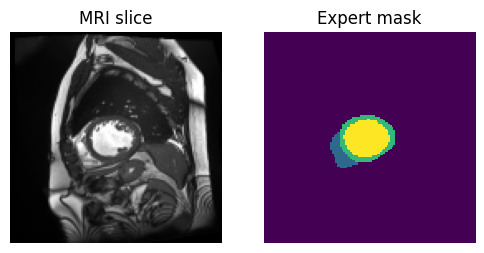

In [25]:
from skimage.transform import resize

IMAGE_SIZE = (128, 128)

def load_preprocessed_phase(patient_id, phase="ED"):
    folder = data_dir / patient_id
    info = read_info(folder / "Info.cfg")
    frame = int(info[phase])

    image_path = folder / f"{patient_id}_frame{frame:02d}.nii.gz"
    mask_path = folder / f"{patient_id}_frame{frame:02d}_gt.nii.gz"

    image_obj = nib.load(image_path)
    mask_obj = nib.load(mask_path)

    image = image_obj.get_fdata(dtype=np.float32)
    raw_mask = mask_obj.get_fdata()

    assert image.shape == raw_mask.shape
    assert np.allclose(image_obj.affine, mask_obj.affine)
    assert np.isfinite(image).all()
    assert np.isin(raw_mask, [0, 1, 2, 3]).all()

    # Normalize each 3D volume independently.
    low, high = np.percentile(image, [1, 99])
    image = np.clip(image, low, high)
    image = (image - image.mean()) / max(float(image.std()), 1e-6)

    # Store slices as (number of slices, height, width).
    images = np.stack([
        resize(
            image[:, :, z],
            IMAGE_SIZE,
            order=1,
            preserve_range=True,
            anti_aliasing=True
        )
        for z in range(image.shape[2])
    ]).astype(np.float32)

    masks = np.stack([
        resize(
            raw_mask[:, :, z],
            IMAGE_SIZE,
            order=0,
            preserve_range=True,
            anti_aliasing=False
        )
        for z in range(raw_mask.shape[2])
    ]).astype(np.uint8)

    return images, masks


patient_ids = sorted(p.name for p in data_dir.glob("patient*")
                     if p.is_dir() and (p / "Info.cfg").is_file())
assert len(patient_ids) == 100, f"Expected 100 development patients; found {len(patient_ids)}."
groups = [read_info(data_dir / pid / "Info.cfg")["Group"] for pid in patient_ids]
volumes = {(pid, phase): load_preprocessed_phase(pid, phase)
           for pid in patient_ids for phase in ("ED", "ES")}
images, masks = volumes[(patient_ids[0], "ED")]
print("Patients:", len(patient_ids), "| Annotated volumes:", len(volumes))
print("Example shapes:", images.shape, masks.shape, "| Labels:", np.unique(masks))
middle = len(images) // 2
fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(images[middle].T, cmap="gray")
axes[0].set_title("MRI slice")
axes[1].imshow(masks[middle].T, vmin=0, vmax=3, interpolation="nearest")
axes[1].set_title("Expert mask")
for ax in axes:
    ax.axis("off")
plt.show()

### 1.3 Create five patient-level folds
Each run trains on 80 patients and validates on 20. Every patient serves as validation once. Stratification balances the diagnosis groups. Both phases and all slices from a patient stay together, and both models use the exact same folds.

In [26]:
splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = []
assignments = []
for fold, (train_idx, val_idx) in enumerate(splitter.split(patient_ids, groups), 1):
    train_ids = [patient_ids[i] for i in train_idx]
    val_ids = [patient_ids[i] for i in val_idx]
    assert set(train_ids).isdisjoint(val_ids)
    folds.append((fold, train_ids, val_ids))
    assignments.extend({"patient_id": patient_ids[i], "group": groups[i], "validation_fold": fold}
                       for i in val_idx)
    print(f"Fold {fold}: train={len(train_ids)}, validation={len(val_ids)}")
pd.DataFrame(assignments).to_csv(output_dir / "patient_folds.csv", index=False)

Fold 1: train=80, validation=20
Fold 2: train=80, validation=20
Fold 3: train=80, validation=20
Fold 4: train=80, validation=20
Fold 5: train=80, validation=20


### 1.4 Check diagnosis labels

In [27]:
diagnosis_labels = pd.DataFrame({
    "patient_id": patient_ids,
    "diagnosis": groups,
})

print("Training patients:", len(diagnosis_labels))
display(diagnosis_labels.head())
display(diagnosis_labels["diagnosis"].value_counts().sort_index())

Training patients: 100


,patient_id,diagnosis
0,patient001,DCM
1,patient002,DCM
2,patient003,DCM
3,patient004,DCM
4,patient005,DCM


,count
diagnosis,
DCM,20
HCM,20
MINF,20
NOR,20
RV,20


### 1.5 Define augmentation for U-Net training
**Augmentation means creating slightly changed versions of existing training images.** Small rotations turn the MRI and matching mask together. Brightness shifts change the MRI alone. Each epoch can show different versions of the same slice. The number of independent patients stays the same. The Random Forest uses the original prepared slices as the baseline, and every validation fold uses unaugmented data.

In [28]:
import numpy as np
import torch
from scipy.ndimage import rotate
from torch.utils.data import Dataset, DataLoader

class AugmentedMRIDataset(Dataset):
    def __init__(self, base_dataset, seed=42):
        self.base_dataset = base_dataset
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, mask = self.base_dataset[index]
        image_array = image[0].numpy().copy()
        mask_array = mask.numpy().copy()

        # Rotate the MRI and its expert mask by the same angle.
        if self.rng.random() < 0.5:
            angle = self.rng.uniform(-10, 10)
            image_array = rotate(
                image_array, angle, reshape=False, order=1, mode="nearest"
            )
            mask_array = rotate(
                mask_array, angle, reshape=False, order=0,
                mode="constant", cval=0
            )

        # Shift MRI brightness slightly in normalized intensity units.
        if self.rng.random() < 0.5:
            image_array += self.rng.uniform(-0.15, 0.15)

        return (
            torch.from_numpy(image_array).float().unsqueeze(0),
            torch.from_numpy(mask_array).long(),
        )


from torch.utils.data import TensorDataset

def make_dataset(ids):
    pairs = [volumes[(pid, phase)] for pid in ids for phase in ("ED", "ES")]
    images = np.concatenate([image for image, _ in pairs])[:, None]
    masks = np.concatenate([mask for _, mask in pairs])
    return TensorDataset(torch.from_numpy(images), torch.from_numpy(masks).long())

CLASS_NAMES = {1: "RV", 2: "Myocardium", 3: "LV"}

def volume_dice(reference, prediction):
    scores = {}
    for label, name in CLASS_NAMES.items():
        ref, pred = reference == label, prediction == label
        total = ref.sum() + pred.sum()
        scores[name] = 2 * np.count_nonzero(ref & pred) / total if total else 1.0
    return scores

def summarize_volumes(rows):
    by_patient = pd.DataFrame(rows).groupby("patient_id")[list(CLASS_NAMES.values())].mean()
    scores = by_patient.mean().to_dict()
    scores["mean_dice"] = float(np.mean(list(scores.values())))
    return scores

def rank_cv(rows, keys):
    return (pd.DataFrame(rows).groupby(keys, as_index=False)
            .agg(RV=("RV", "mean"), Myocardium=("Myocardium", "mean"),
                 LV=("LV", "mean"), mean_dice=("mean_dice", "mean"),
                 fold_sd=("mean_dice", "std"))
            .sort_values("mean_dice", ascending=False))

## 2. Random Forest models

Each pixel is represented by six features describing brightness, nearby variation, edges, and position. **Grid search** tries every combination in a small, predefined list. It gives a clear comparison because all candidates see the same five folds. The search varies tree count and maximum depth and holds the minimum leaf size at 1.

**Dice** measures overlap between the prediction and expert mask. It ranges from 0 (no overlap) to 1 (perfect overlap). For each heart structure we score complete resized volumes, average ED and ES within each patient, then average across patients. Mean foreground Dice averages the three structure scores and excludes background. If both regions are empty, Dice is 1. If only one is empty, Dice is 0.

### 2.1 Extract features for segmentation

In [29]:
from scipy.ndimage import uniform_filter, sobel

FEATURE_NAMES = [
    "intensity",
    "local_mean_5x5",
    "local_std_5x5",
    "gradient_magnitude",
    "row_position",
    "column_position"
]

def extract_features(image_slice):
    image_slice = np.asarray(image_slice, dtype=np.float32)

    local_mean = uniform_filter(image_slice, size=5, mode="reflect")
    local_mean_squared = uniform_filter(
        image_slice ** 2, size=5, mode="reflect"
    )
    local_std = np.sqrt(
        np.maximum(local_mean_squared - local_mean ** 2, 0)
    )

    gradient_row = sobel(image_slice, axis=0, mode="reflect")
    gradient_col = sobel(image_slice, axis=1, mode="reflect")
    gradient = np.hypot(gradient_row, gradient_col)

    height, width = image_slice.shape
    rows, cols = np.meshgrid(
        np.linspace(0, 1, height, dtype=np.float32),
        np.linspace(0, 1, width, dtype=np.float32),
        indexing="ij"
    )

    features = np.stack([
        image_slice,
        local_mean,
        local_std,
        gradient,
        rows,
        cols
    ], axis=-1)

    return features.reshape(-1, len(FEATURE_NAMES)).astype(np.float32)


from sklearn.ensemble import RandomForestClassifier
import joblib

PIXELS_PER_CLASS_PHASE = 250

def sample_rf_pixels(ids):
    rng = np.random.default_rng(SEED)
    features, labels = [], []
    pixels_per_slice = int(np.prod(IMAGE_SIZE))

    # Use the same rotation and brightness rules as U-Net.
    augmented = AugmentedMRIDataset(make_dataset(ids), seed=SEED)
    offset = 0

    def sample_volume(images, masks):
        flat_labels = masks.ravel()

        for label in range(4):
            candidates = np.flatnonzero(flat_labels == label)
            count = min(len(candidates), PIXELS_PER_CLASS_PHASE)
            if count == 0:
                continue

            chosen = rng.choice(candidates, size=count, replace=False)
            slice_ids, pixel_ids = np.divmod(chosen, pixels_per_slice)

            for z in np.unique(slice_ids):
                keep = slice_ids == z
                # Calculate features from the same image version as the mask.
                features.append(extract_features(images[z])[pixel_ids[keep]])
                labels.append(flat_labels[chosen[keep]])

    for patient_id in ids:
        for phase in ("ED", "ES"):
            images, masks = volumes[(patient_id, phase)]

            # Sample pixels from the original volume.
            sample_volume(images, masks)

            # Sample pixels from one randomly augmented version.
            augmented_images = []
            augmented_masks = []
            for z in range(len(images)):
                image, mask = augmented[offset + z]
                augmented_images.append(image[0].numpy())
                augmented_masks.append(mask.numpy())

            sample_volume(np.stack(augmented_images), np.stack(augmented_masks))
            offset += len(images)

    assert offset == len(augmented)
    return np.concatenate(features), np.concatenate(labels)

def rf_model(params):
    return RandomForestClassifier(**params, min_samples_leaf=1,
                                  max_features="sqrt", random_state=SEED, n_jobs=-1)

### 2.2 Tune the segmentation Random Forest

In [30]:
rf_grid = list(ParameterGrid({"n_estimators": [100, 200], "max_depth": [15, 25]}))
rf_rows = []
for fold, train_ids, val_ids in folds:
    X_train, y_train = sample_rf_pixels(train_ids)
    # Cache only this fold's full validation features.
    val_features = {
        (pid, phase): np.concatenate([extract_features(img)
                                      for img in volumes[(pid, phase)][0]])
        for pid in val_ids for phase in ("ED", "ES")
    }
    for params in rf_grid:
        start = time.perf_counter()
        model = rf_model(params).fit(X_train, y_train)
        rows = []
        for (pid, phase), features in val_features.items():
            reference = volumes[(pid, phase)][1]
            prediction = model.predict(features).reshape(reference.shape)
            rows.append({"patient_id": pid, **volume_dice(reference, prediction)})
        scores = summarize_volumes(rows)
        rf_rows.append({"fold": fold, **params, **scores, "seconds": time.perf_counter() - start})
        pd.DataFrame(rf_rows).to_csv(output_dir / "rf_cv_folds.csv", index=False)
        print(f"RF fold {fold} | {params} | Dice {scores['mean_dice']:.4f}", flush=True)
        del model
    del val_features, X_train, y_train

rf_summary = rank_cv(rf_rows, ["n_estimators", "max_depth"])
display(rf_summary.round(4))
rf_summary.to_csv(output_dir / "rf_cv_summary.csv", index=False)
rf_best = {key: int(rf_summary.iloc[0][key]) for key in ("n_estimators", "max_depth")}

RF fold 1 | {'max_depth': 15, 'n_estimators': 100} | Dice 0.3814
RF fold 1 | {'max_depth': 15, 'n_estimators': 200} | Dice 0.3821
RF fold 1 | {'max_depth': 25, 'n_estimators': 100} | Dice 0.3987
RF fold 1 | {'max_depth': 25, 'n_estimators': 200} | Dice 0.3994
RF fold 2 | {'max_depth': 15, 'n_estimators': 100} | Dice 0.3588
RF fold 2 | {'max_depth': 15, 'n_estimators': 200} | Dice 0.3591
RF fold 2 | {'max_depth': 25, 'n_estimators': 100} | Dice 0.3708
RF fold 2 | {'max_depth': 25, 'n_estimators': 200} | Dice 0.3713
RF fold 3 | {'max_depth': 15, 'n_estimators': 100} | Dice 0.4109
RF fold 3 | {'max_depth': 15, 'n_estimators': 200} | Dice 0.4107
RF fold 3 | {'max_depth': 25, 'n_estimators': 100} | Dice 0.4209
RF fold 3 | {'max_depth': 25, 'n_estimators': 200} | Dice 0.4214
RF fold 4 | {'max_depth': 15, 'n_estimators': 100} | Dice 0.3786
RF fold 4 | {'max_depth': 15, 'n_estimators': 200} | Dice 0.3788
RF fold 4 | {'max_depth': 25, 'n_estimators': 100} | Dice 0.3891
RF fold 4 | {'max_depth':

,n_estimators,max_depth,RV,Myocardium,LV,mean_dice,fold_sd
3,200,25,0.2971,0.3431,0.5317,0.3907,0.0210
1,100,25,0.2969,0.3428,0.5308,0.3902,0.0209
2,200,15,0.2875,0.3226,0.5259,0.3786,0.0205
0,100,15,0.2873,0.3227,0.5254,0.3785,0.0206


### 2.3 Train and validate the diagnosis Random Forest

In [10]:
from skimage.transform import resize

def patient_mri_features(patient_id):
    features = []

    for phase in ("ED", "ES"):
        images, _ = load_preprocessed_phase(patient_id, phase)

        # Select slices around 25%, 50%, and 75% of the way through the scan.
        slice_indices = np.rint(
            np.array([0.25, 0.50, 0.75]) * (len(images) - 1)
        ).astype(int)

        for slice_index in slice_indices:
            small_image = resize(
                images[slice_index],
                (16, 16),
                anti_aliasing=True,
            )
            features.extend(small_image.ravel())

    return features

rf_diagnosis_features = pd.DataFrame(
    [patient_mri_features(pid) for pid in diagnosis_labels["patient_id"]],
    index=diagnosis_labels["patient_id"],
)

print("Diagnosis feature table shape:", rf_diagnosis_features.shape)
display(rf_diagnosis_features.iloc[:5, :8])

Diagnosis feature table shape: (100, 1536)


,0,1,2,3,4,5,6,7
patient_id,,,,,,,,
patient001,-0.590928,-0.512980,-0.607252,-0.767939,-0.804515,-0.801753,-0.811601,-0.817308
patient002,-1.046701,-1.022622,-1.016544,-0.975388,-1.006619,-1.018268,-1.021995,-1.012525
patient003,-0.831780,-0.821386,-0.815414,-0.807123,-0.768899,-0.155414,0.687305,0.758874
patient004,-0.891208,-0.891911,-0.891627,-0.889750,-0.887816,-0.885364,-0.889160,-0.889243
patient005,-0.915298,-0.888542,-0.872702,-0.696027,-0.323981,-0.500395,-0.436031,-0.100390


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

diagnosis_targets = diagnosis_labels.set_index("patient_id")["diagnosis"]

rf_diagnosis_grid = list(ParameterGrid({
    "n_estimators": [100, 200],
    "max_depth": [5, 15],
}))

rf_diagnosis_rows = []

for params in rf_diagnosis_grid:
    for fold, train_ids, val_ids in folds:
        model = RandomForestClassifier(
            **params, random_state=SEED, n_jobs=-1
        )
        model.fit(
            rf_diagnosis_features.loc[train_ids],
            diagnosis_targets.loc[train_ids],
        )

        predictions = model.predict(rf_diagnosis_features.loc[val_ids])
        targets = diagnosis_targets.loc[val_ids]

        rf_diagnosis_rows.append({
            **params,
            "fold": fold,
            "accuracy": accuracy_score(targets, predictions),
            "macro_f1": f1_score(
                targets, predictions, average="macro", zero_division=0
            ),
        })

rf_diagnosis_summary = (
    pd.DataFrame(rf_diagnosis_rows)
    .groupby(["n_estimators", "max_depth"], as_index=False)
    .agg(
        mean_accuracy=("accuracy", "mean"),
        mean_macro_f1=("macro_f1", "mean"),
        macro_f1_sd=("macro_f1", "std"),
    )
    .sort_values("mean_macro_f1", ascending=False)
    .reset_index(drop=True)
)

rf_diagnosis_best = {
    name: int(rf_diagnosis_summary.loc[0, name])
    for name in ("n_estimators", "max_depth")
}

display(rf_diagnosis_summary.round(4))
print("Best diagnosis Random Forest settings:", rf_diagnosis_best)

,n_estimators,max_depth,mean_accuracy,mean_macro_f1,macro_f1_sd
0,200,15,0.37,0.3577,0.1380
1,100,15,0.33,0.3063,0.0780
2,100,5,0.32,0.3001,0.0953
3,200,5,0.32,0.2938,0.0671


Best diagnosis Random Forest settings: {'n_estimators': 200, 'max_depth': 15}


## 3. U-Net and CNN models

U-Net learns to draw a mask from an MRI slice. The **encoder** shrinks feature maps so the network can see broader patterns. The **decoder** enlarges them to label each pixel. **Skip connections** pass fine details from the encoder to the decoder to help draw boundaries. Our model starts with random weights.

We tune by comparing controlled training runs. At learning rate 0.001 we try training with and without augmentation. With augmentation we also try 0.0003 and 0.003. The architecture, folds, batch size (16), and budget (20 epochs) are shared. Each candidate is judged at epoch 20 on every fold to apply the same selection rule. We train with cross-entropy plus foreground Dice loss and evaluate with the same hard-mask Dice as Random Forest.

### 3.1 Build the segmentation U-Net

In [12]:
import torch
from torch import nn

def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(),
    )

class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder1 = conv_block(1, 16)
        self.encoder2 = conv_block(16, 32)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = conv_block(32, 64)

        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.decoder2 = conv_block(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.decoder1 = conv_block(32, 16)

        self.classifier = nn.Conv2d(16, 4, kernel_size=1)

    def forward(self, x):
        features1 = self.encoder1(x)
        features2 = self.encoder2(self.pool(features1))
        center = self.bottleneck(self.pool(features2))

        decoded2 = self.decoder2(
            torch.cat([self.up2(center), features2], dim=1)
        )
        decoded1 = self.decoder1(
            torch.cat([self.up1(decoded2), features1], dim=1)
        )
        return self.classifier(decoded1)


from torch.nn import functional as F

def loss_for_batch(logits, masks):
    probabilities = logits.softmax(dim=1)[:, 1:]
    targets = F.one_hot(masks, num_classes=4).permute(0, 3, 1, 2)
    targets = targets[:, 1:].float()

    dims = (0, 2, 3)
    overlap = (probabilities * targets).sum(dim=dims)
    total = probabilities.sum(dim=dims) + targets.sum(dim=dims)
    dice = (2 * overlap + 1e-6) / (total + 1e-6)

    return F.cross_entropy(logits, masks) + (1 - dice.mean())

### 3.2 Train and validate the segmentation U-Net

In [13]:
EPOCHS = 20
BATCH_SIZE = 16
unet_grid = [(False, 0.001), (True, 0.001), (True, 0.0003), (True, 0.003)]

def fit_unet(dataset, augment, learning_rate):
    torch.manual_seed(SEED)
    training = AugmentedMRIDataset(dataset, seed=SEED) if augment else dataset
    loader = DataLoader(training, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED), num_workers=0)
    model = SmallUNet().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            loss = loss_for_batch(model(images), masks)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(images)
        if epoch in (1, 5, 10, 15, EPOCHS):
            print(f"  Epoch {epoch:02d} | loss {loss_sum / len(dataset):.4f}", flush=True)
    return model

@torch.inference_mode()
def predict_unet(model, images):
    model.eval()
    tensor = torch.from_numpy(images[:, None])
    batches = [model(batch.to(device)).argmax(dim=1).cpu().numpy()
               for batch in tensor.split(BATCH_SIZE)]
    return np.concatenate(batches)

unet_rows = []
for fold, train_ids, val_ids in folds:
    train_dataset = make_dataset(train_ids)
    for augment, learning_rate in unet_grid:
        print(f"U-Net fold {fold} | augmentation={augment} | LR={learning_rate}", flush=True)
        start = time.perf_counter()
        model = fit_unet(train_dataset, augment, learning_rate)
        rows = []
        for pid in val_ids:
            for phase in ("ED", "ES"):
                images, reference = volumes[(pid, phase)]
                prediction = predict_unet(model, images)
                rows.append({"patient_id": pid, **volume_dice(reference, prediction)})
        scores = summarize_volumes(rows)
        unet_rows.append({"fold": fold, "augment": augment, "learning_rate": learning_rate,
                          **scores, "seconds": time.perf_counter() - start})
        pd.DataFrame(unet_rows).to_csv(output_dir / "unet_cv_folds.csv", index=False)
        print(f"  Validation Dice: {scores['mean_dice']:.4f}", flush=True)
        del model
    del train_dataset

unet_summary = rank_cv(unet_rows, ["augment", "learning_rate"])
display(unet_summary.round(4))
unet_summary.to_csv(output_dir / "unet_cv_summary.csv", index=False)

U-Net fold 1 | augmentation=False | LR=0.001
  Epoch 01 | loss 1.2955
  Epoch 05 | loss 0.4612
  Epoch 10 | loss 0.2349
  Epoch 15 | loss 0.1697
  Epoch 20 | loss 0.1323
  Validation Dice: 0.8381
U-Net fold 1 | augmentation=True | LR=0.001
  Epoch 01 | loss 1.2981
  Epoch 05 | loss 0.4983
  Epoch 10 | loss 0.2485
  Epoch 15 | loss 0.1911
  Epoch 20 | loss 0.1568
  Validation Dice: 0.8331
U-Net fold 1 | augmentation=True | LR=0.0003
  Epoch 01 | loss 1.5508
  Epoch 05 | loss 0.7533
  Epoch 10 | loss 0.5258
  Epoch 15 | loss 0.4019
  Epoch 20 | loss 0.3353
  Validation Dice: 0.7168
U-Net fold 1 | augmentation=True | LR=0.003
  Epoch 01 | loss 1.1810
  Epoch 05 | loss 0.3827
  Epoch 10 | loss 0.2122
  Epoch 15 | loss 0.1665
  Epoch 20 | loss 0.1421
  Validation Dice: 0.8511
U-Net fold 2 | augmentation=False | LR=0.001
  Epoch 01 | loss 1.2927
  Epoch 05 | loss 0.4227
  Epoch 10 | loss 0.2115
  Epoch 15 | loss 0.1512
  Epoch 20 | loss 0.1273
  Validation Dice: 0.7995
U-Net fold 2 | augment

,augment,learning_rate,RV,Myocardium,LV,mean_dice,fold_sd
3,True,0.0030,0.8049,0.7998,0.8746,0.8264,0.0263
2,True,0.0010,0.7889,0.7814,0.8769,0.8157,0.0181
0,False,0.0010,0.7904,0.7805,0.8670,0.8126,0.0216
1,True,0.0003,0.5873,0.6424,0.7835,0.6710,0.0427


### 3.3 Train and validate the six-slice diagnosis CNN

In [14]:
# Prepare the CNN inputs and check the model's output shape.

def patient_mri_stack(patient_id):
    slices = []

    for phase in ("ED", "ES"):
        images, _ = load_preprocessed_phase(patient_id, phase)
        indices = np.rint(
            np.array([0.25, 0.50, 0.75]) * (len(images) - 1)
        ).astype(int)
        slices.extend(images[indices])

    return np.stack(slices).astype(np.float32)


class DiagnosisCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.encoder = nn.Sequential(
            conv_block(6, 16),
            nn.MaxPool2d(2),
            conv_block(16, 32),
            nn.MaxPool2d(2),
            conv_block(32, 64),
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, num_classes),
        )

    def forward(self, images):
        return self.classifier(self.encoder(images))


diagnosis_classes = sorted(diagnosis_targets.unique())

example_stack = torch.from_numpy(patient_mri_stack(patient_ids[0]))
example_batch = example_stack.unsqueeze(0).to(device)

diagnosis_cnn_check = DiagnosisCNN(len(diagnosis_classes)).to(device)
diagnosis_cnn_check.eval()

with torch.no_grad():
    example_scores = diagnosis_cnn_check(example_batch)

print("Diagnosis groups:", diagnosis_classes)
print("CNN input shape:", tuple(example_batch.shape))
print("CNN output shape:", tuple(example_scores.shape))

Diagnosis groups: ['DCM', 'HCM', 'MINF', 'NOR', 'RV']
CNN input shape: (1, 6, 128, 128)
CNN output shape: (1, 5)


In [15]:
from torch.utils.data import DataLoader, TensorDataset

# Build one MRI stack and one diagnosis label per patient.
diagnosis_patient_ids = diagnosis_targets.index.tolist()
diagnosis_row_by_id = {
    patient_id: row for row, patient_id in enumerate(diagnosis_patient_ids)
}
diagnosis_class_to_index = {
    group: index for index, group in enumerate(diagnosis_classes)
}

diagnosis_x = torch.from_numpy(np.stack([
    patient_mri_stack(patient_id) for patient_id in diagnosis_patient_ids
]))
diagnosis_y = torch.tensor([
    diagnosis_class_to_index[diagnosis_targets.loc[patient_id]]
    for patient_id in diagnosis_patient_ids
], dtype=torch.long)

DIAGNOSIS_EPOCHS = 20
DIAGNOSIS_BATCH_SIZE = 8

def train_diagnosis_cnn(train_ids, learning_rate, seed):
    torch.manual_seed(seed)

    rows = [diagnosis_row_by_id[patient_id] for patient_id in train_ids]
    train_loader = DataLoader(
        TensorDataset(diagnosis_x[rows], diagnosis_y[rows]),
        batch_size=DIAGNOSIS_BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    model = DiagnosisCNN(len(diagnosis_classes)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    loss_fn = nn.CrossEntropyLoss()

    model.train()
    for _ in range(DIAGNOSIS_EPOCHS):
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(images), labels)
            loss.backward()
            optimizer.step()

    return model


@torch.no_grad()
def predict_diagnosis_cnn(model, images):
    model.eval()
    predictions = []
    for batch in images.split(DIAGNOSIS_BATCH_SIZE):
        predicted_indices = model(batch.to(device)).argmax(dim=1).cpu().tolist()
        predictions.extend(diagnosis_classes[index] for index in predicted_indices)
    return predictions


cnn_diagnosis_rows = []

for learning_rate in (0.001, 0.0003):
    for fold, train_ids, val_ids in folds:
        model = train_diagnosis_cnn(train_ids, learning_rate, SEED + fold)

        val_rows = [diagnosis_row_by_id[patient_id] for patient_id in val_ids]
        predictions = predict_diagnosis_cnn(model, diagnosis_x[val_rows])
        targets = diagnosis_targets.loc[val_ids]

        accuracy = accuracy_score(targets, predictions)
        macro_f1 = f1_score(
            targets, predictions,
            labels=diagnosis_classes, average="macro", zero_division=0,
        )

        cnn_diagnosis_rows.append({
            "learning_rate": learning_rate,
            "fold": fold,
            "accuracy": accuracy,
            "macro_f1": macro_f1,
        })
        print(
            f"LR {learning_rate:g} | Fold {fold} | "
            f"Accuracy {accuracy:.2%} | Macro F1 {macro_f1:.4f}",
            flush=True,
        )

cnn_diagnosis_summary = (
    pd.DataFrame(cnn_diagnosis_rows)
    .groupby("learning_rate", as_index=False)
    .agg(
        mean_accuracy=("accuracy", "mean"),
        mean_macro_f1=("macro_f1", "mean"),
        macro_f1_sd=("macro_f1", "std"),
    )
    .sort_values("mean_macro_f1", ascending=False)
    .reset_index(drop=True)
)

cnn_diagnosis_best_lr = float(cnn_diagnosis_summary.loc[0, "learning_rate"])

display(cnn_diagnosis_summary.round(4))
print("Best diagnosis CNN learning rate:", cnn_diagnosis_best_lr)

LR 0.001 | Fold 1 | Accuracy 30.00% | Macro F1 0.1905
LR 0.001 | Fold 2 | Accuracy 20.00% | Macro F1 0.0667
LR 0.001 | Fold 3 | Accuracy 30.00% | Macro F1 0.1867
LR 0.001 | Fold 4 | Accuracy 25.00% | Macro F1 0.1433
LR 0.001 | Fold 5 | Accuracy 30.00% | Macro F1 0.2267
LR 0.0003 | Fold 1 | Accuracy 20.00% | Macro F1 0.1100
LR 0.0003 | Fold 2 | Accuracy 20.00% | Macro F1 0.1571
LR 0.0003 | Fold 3 | Accuracy 10.00% | Macro F1 0.0444
LR 0.0003 | Fold 4 | Accuracy 20.00% | Macro F1 0.0667
LR 0.0003 | Fold 5 | Accuracy 20.00% | Macro F1 0.0800


,learning_rate,mean_accuracy,mean_macro_f1,macro_f1_sd
0,0.0010,0.27,0.1628,0.0613
1,0.0003,0.18,0.0917,0.0436


Best diagnosis CNN learning rate: 0.001


### 3.4 Classify diagnoses using U-Net heart measurements

In [16]:
# 3.3 — Diagnosis using measurements from U-Net predictions

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def predicted_heart_features(segmentation_model, patient_id):
    folder = data_dir / patient_id
    info = read_info(folder / "Info.cfg")
    features = {}

    for phase in ("ED", "ES"):
        images, _ = volumes[(patient_id, phase)]
        prediction = predict_unet(segmentation_model, images)

        # Convert counts on the resized grid into approximate milliliters.
        frame = int(info[phase])
        original = nib.load(folder / f"{patient_id}_frame{frame:02d}.nii.gz")
        original_voxel_mm3 = abs(np.linalg.det(original.affine[:3, :3]))
        resize_factor = (
            original.shape[0] * original.shape[1]
            / (prediction.shape[1] * prediction.shape[2])
        )
        ml_per_voxel = original_voxel_mm3 * resize_factor / 1000

        for structure, label in (("rv", 1), ("muscle", 2), ("lv", 3)):
            features[f"{structure}_{phase.lower()}_ml"] = (
                np.count_nonzero(prediction == label) * ml_per_voxel
            )

    for chamber in ("lv", "rv"):
        ed = features[f"{chamber}_ed_ml"]
        es = features[f"{chamber}_es_ml"]
        features[f"{chamber}_emptying_fraction"] = (ed - es) / ed if ed else np.nan

    return features


def heart_feature_table(segmentation_model, ids):
    return pd.DataFrame(
        [predicted_heart_features(segmentation_model, pid) for pid in ids],
        index=ids,
    )


unet_diagnosis_fold_results = []

for fold, train_ids, val_ids in folds:
    print(f"Fold {fold}: training the segmentation U-Net", flush=True)

    # Only this fold's 80 training patients contribute expert masks.
    fold_unet = fit_unet(
        make_dataset(train_ids),
        augment=True,
        learning_rate=0.003,
    )

    train_features = heart_feature_table(fold_unet, train_ids)
    val_features = heart_feature_table(fold_unet, val_ids)

    diagnosis_head = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=SEED),
    )
    diagnosis_head.fit(train_features, diagnosis_targets.loc[train_ids])

    predictions = diagnosis_head.predict(val_features)
    targets = diagnosis_targets.loc[val_ids]
    accuracy = accuracy_score(targets, predictions)
    macro_f1 = f1_score(
        targets, predictions,
        labels=diagnosis_classes, average="macro", zero_division=0,
    )

    unet_diagnosis_fold_results.append({
        "fold": fold,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
    })
    print(f"Fold {fold} | Accuracy {accuracy:.1%} | Macro F1 {macro_f1:.4f}")
    del fold_unet

unet_diagnosis_results = pd.DataFrame(unet_diagnosis_fold_results)
display(unet_diagnosis_results.round(4))

print("Mean accuracy:", round(unet_diagnosis_results["accuracy"].mean(), 4))
print("Mean macro F1:", round(unet_diagnosis_results["macro_f1"].mean(), 4))

Fold 1: training the segmentation U-Net
  Epoch 01 | loss 1.1804
  Epoch 05 | loss 0.3486
  Epoch 10 | loss 0.2072
  Epoch 15 | loss 0.1685
  Epoch 20 | loss 0.1417
Fold 1 | Accuracy 80.0% | Macro F1 0.7933
Fold 2: training the segmentation U-Net
  Epoch 01 | loss 1.1937
  Epoch 05 | loss 0.3471
  Epoch 10 | loss 0.2018
  Epoch 15 | loss 0.1600
  Epoch 20 | loss 0.1417
Fold 2 | Accuracy 75.0% | Macro F1 0.7533
Fold 3: training the segmentation U-Net
  Epoch 01 | loss 1.1857
  Epoch 05 | loss 0.3275
  Epoch 10 | loss 0.1940
  Epoch 15 | loss 0.1512
  Epoch 20 | loss 0.1371
Fold 3 | Accuracy 80.0% | Macro F1 0.7957
Fold 4: training the segmentation U-Net
  Epoch 01 | loss 1.1839
  Epoch 05 | loss 0.3140
  Epoch 10 | loss 0.2225
  Epoch 15 | loss 0.1558
  Epoch 20 | loss 0.1362
Fold 4 | Accuracy 95.0% | Macro F1 0.9492
Fold 5: training the segmentation U-Net
  Epoch 01 | loss 1.2060
  Epoch 05 | loss 0.3783
  Epoch 10 | loss 0.2187
  Epoch 15 | loss 0.1659
  Epoch 20 | loss 0.1469
Fold 5 

,fold,accuracy,macro_f1
0,1,0.80,0.7933
1,2,0.75,0.7533
2,3,0.80,0.7957
3,4,0.95,0.9492
4,5,0.70,0.7059


Mean accuracy: 0.8
Mean macro F1: 0.7995


## 4. Final model comparison and testing

### 4.1 Compare five-fold validation results

In [31]:
import joblib

segmentation_columns = ["RV", "Myocardium", "LV", "mean_dice", "fold_sd"]

segmentation_cv = pd.DataFrame([
    {"model": "Random Forest", **rf_summary.iloc[0][segmentation_columns].to_dict()},
    {"model": "U-Net", **unet_summary.iloc[0][segmentation_columns].to_dict()},
])

diagnosis_columns = ["mean_accuracy", "mean_macro_f1", "macro_f1_sd"]

diagnosis_cv = pd.DataFrame([
    {
        "model": "Random Forest",
        **rf_diagnosis_summary.iloc[0][diagnosis_columns].to_dict(),
    },
    {
        "model": "U-Net + heart measurements",
        "mean_accuracy": unet_diagnosis_results["accuracy"].mean(),
        "mean_macro_f1": unet_diagnosis_results["macro_f1"].mean(),
        "macro_f1_sd": unet_diagnosis_results["macro_f1"].std(),
    },
])

print("Segmentation — five-fold validation")
display(segmentation_cv.round(4))

print("Diagnosis — five-fold validation")
display(diagnosis_cv.round(4))

segmentation_cv.to_csv(output_dir / "model_comparison_cv.csv", index=False)
diagnosis_cv.to_csv(output_dir / "diagnosis_cv_comparison.csv", index=False)

Segmentation — five-fold validation


,model,RV,Myocardium,LV,mean_dice,fold_sd
0,Random Forest,0.2971,0.3431,0.5317,0.3907,0.0210
1,U-Net,0.8049,0.7998,0.8746,0.8264,0.0263


Diagnosis — five-fold validation


,model,mean_accuracy,mean_macro_f1,macro_f1_sd
0,Random Forest,0.37,0.3577,0.1380
1,U-Net + heart measurements,0.80,0.7995,0.0913


In [32]:
display(unet_summary.iloc[0][["augment", "learning_rate"]])

,3
augment,True
learning_rate,0.003


### 4.2 Train and save the final models

In [33]:
# Segmentation models
X_seg, y_seg = sample_rf_pixels(patient_ids)
final_rf = rf_model(rf_best).fit(X_seg, y_seg)
del X_seg, y_seg

unet_best = unet_summary.iloc[0]
final_unet = fit_unet(
    make_dataset(patient_ids),
    augment=bool(unet_best["augment"]),
    learning_rate=float(unet_best["learning_rate"]),
)

# Diagnosis models
final_diagnosis_rf = RandomForestClassifier(
    **rf_diagnosis_best, random_state=SEED, n_jobs=-1
)
final_diagnosis_rf.fit(
    rf_diagnosis_features.loc[diagnosis_patient_ids],
    diagnosis_targets.loc[diagnosis_patient_ids],
)

final_heart_head = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=SEED),
)
train_heart_features = heart_feature_table(final_unet, diagnosis_patient_ids)
final_heart_head.fit(
    train_heart_features,
    diagnosis_targets.loc[diagnosis_patient_ids],
)

# Save the model files.
joblib.dump(final_rf, output_dir / "final_random_forest.joblib")
torch.save(final_unet.state_dict(), output_dir / "final_unet.pt")
joblib.dump(final_diagnosis_rf, output_dir / "final_diagnosis_rf.joblib")
joblib.dump(final_heart_head, output_dir / "final_unet_diagnosis_head.joblib")

print("Saved all four model files to:", output_dir)

  Epoch 01 | loss 1.1257
  Epoch 05 | loss 0.2764
  Epoch 10 | loss 0.1753
  Epoch 15 | loss 0.1551
  Epoch 20 | loss 0.1316
Saved all four model files to: /content/drive/MyDrive/ACDC_Project/results/organized_cv


### 4.3 Prepare the held-out test data

In [34]:
import re
from zipfile import ZipFile

test_zip = Path("/content/drive/MyDrive/testing.zip")
test_extract_dir = Path("/content/acdc_test")
test_dir = test_extract_dir / "testing"

assert test_zip.is_file(), f"Could not find {test_zip}"

test_file_pattern = re.compile(
    r"testing/(patient\d+)/(?:Info\.cfg|\1_frame\d+(?:_gt)?\.nii\.gz)"
)

with ZipFile(test_zip) as archive:
    selected = [
        name for name in archive.namelist()
        if test_file_pattern.fullmatch(name)
    ]
    test_ids = sorted({
        name.split("/")[1] for name in selected if name.endswith("/Info.cfg")
    })

    assert len(test_ids) == 50, f"Expected 50 test patients, found {len(test_ids)}"
    assert set(test_ids).isdisjoint(patient_ids), "Development and test IDs overlap."
    archive.extractall(test_extract_dir, members=selected)

test_diagnoses = pd.Series({
    pid: read_info(test_dir / pid / "Info.cfg")["Group"]
    for pid in test_ids
}, name="diagnosis")

assert set(test_diagnoses) == set(diagnosis_classes), "Check the test diagnosis labels."

training_data_dir = data_dir
try:
    data_dir = test_dir

    test_volumes = {
        (pid, phase): load_preprocessed_phase(pid, phase)
        for pid in test_ids
        for phase in ("ED", "ES")
    }

    test_rf_features = pd.DataFrame(
        [patient_mri_features(pid) for pid in test_ids],
        index=test_ids,
        columns=rf_diagnosis_features.columns,
    )
finally:
    data_dir = training_data_dir

print("Test patients:", len(test_ids))
print("Test MRI volumes and matching masks:", len(test_volumes))
display(test_diagnoses.value_counts().sort_index())

Test patients: 50
Test MRI volumes and matching masks: 100


,count
diagnosis,
DCM,10
HCM,10
MINF,10
NOR,10
RV,10


### 4.4 Evaluate both segmentation models

In [35]:
segmentation_test_rows = {"Random Forest": [], "U-Net": []}

for number, pid in enumerate(test_ids, start=1):
    for phase in ("ED", "ES"):
        images, reference = test_volumes[(pid, phase)]

        rf_prediction = np.stack([
            final_rf.predict(extract_features(image)).reshape(image.shape)
            for image in images
        ])
        unet_prediction = predict_unet(final_unet, images)

        for model_name, prediction in (
            ("Random Forest", rf_prediction),
            ("U-Net", unet_prediction),
        ):
            segmentation_test_rows[model_name].append({
                "patient_id": pid,
                "phase": phase,
                **volume_dice(reference, prediction),
            })

    if number % 10 == 0:
        print(f"Evaluated {number}/{len(test_ids)} test patients", flush=True)

segmentation_test_results = pd.DataFrame([
    {"model": name, **summarize_volumes(rows)}
    for name, rows in segmentation_test_rows.items()
])

display(segmentation_test_results.round(4))
segmentation_test_results.to_csv(
    output_dir / "model_comparison_test.csv", index=False
)

Evaluated 10/50 test patients
Evaluated 20/50 test patients
Evaluated 30/50 test patients
Evaluated 40/50 test patients
Evaluated 50/50 test patients


,model,RV,Myocardium,LV,mean_dice
0,Random Forest,0.2918,0.3206,0.4942,0.3689
1,U-Net,0.8336,0.8144,0.8836,0.8438


### 4.5 Evaluate both diagnosis models

In [36]:
from sklearn.metrics import confusion_matrix

# Temporarily point the existing heart-feature helper at the test scans.
training_data_dir = data_dir
training_volumes = volumes
try:
    data_dir = test_dir
    volumes = test_volumes
    test_heart_features = heart_feature_table(final_unet, test_ids)
finally:
    data_dir = training_data_dir
    volumes = training_volumes

diagnosis_test_predictions = {
    "Random Forest": final_diagnosis_rf.predict(test_rf_features.loc[test_ids]),
    "U-Net + heart measurements": final_heart_head.predict(
        test_heart_features.loc[test_ids]
    ),
}

true_groups = test_diagnoses.loc[test_ids]

diagnosis_test_results = pd.DataFrame([
    {
        "model": name,
        "accuracy": accuracy_score(true_groups, predictions),
        "macro_f1": f1_score(
            true_groups,
            predictions,
            labels=diagnosis_classes,
            average="macro",
            zero_division=0,
        ),
    }
    for name, predictions in diagnosis_test_predictions.items()
])

display(diagnosis_test_results.round(4))
diagnosis_test_results.to_csv(
    output_dir / "diagnosis_test_results.csv", index=False
)

for name, predictions in diagnosis_test_predictions.items():
    matrix = pd.DataFrame(
        confusion_matrix(true_groups, predictions, labels=diagnosis_classes),
        index=pd.Index(diagnosis_classes, name="True group"),
        columns=pd.Index(diagnosis_classes, name="Predicted group"),
    )
    print(name)
    display(matrix)

    filename = (
        "diagnosis_rf_confusion_test.csv"
        if name == "Random Forest"
        else "diagnosis_unet_confusion_test.csv"
    )
    matrix.to_csv(output_dir / filename)

,model,accuracy,macro_f1
0,Random Forest,0.46,0.4482
1,U-Net + heart measurements,0.82,0.8189


Random Forest


Predicted group,DCM,HCM,MINF,NOR,RV
True group,,,,,
DCM,6,1,2,0,1
HCM,1,4,3,2,0
MINF,2,3,3,1,1
NOR,0,4,1,2,3
RV,0,1,0,1,8


U-Net + heart measurements


Predicted group,DCM,HCM,MINF,NOR,RV
True group,,,,,
DCM,8,0,1,0,1
HCM,0,10,0,0,0
MINF,3,0,7,0,0
NOR,0,0,1,9,0
RV,0,0,0,3,7
